# Chapter 12 · The Feynman–Kac formula: interactive demos

Companion to Chapter 12 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/12-feynman-kac.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider

from ieor222.blackscholes import call, digital_call
from ieor222.feynmankac import (bm_density, digital_delta, gbm_density, heat_solution,
                                kolmogorov_residuals, local_vol_mc, price_at, skew_vol,
                                solve_pricing_pde)
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()

## 1. The same price two ways: Monte Carlo and a PDE

In the local volatility model $dS_t=rS_t\,dt+\sigma(S_t)S_t\,d\widetilde W_t$ with the skew
$\sigma(x)=\text{level}-\text{skew}\cdot\tanh(2\log(x/100))$, the call price $v(0,x)=e^{-rT}\mathbb E^{\mathbb Q}[(S_T-K)^+\mid S_0=x]$
is computed two ways (Corollary 12.4):

* **PDE:** one Crank–Nicolson solution of $\partial_tv+rx\,\partial_xv+\tfrac12\sigma(x)^2x^2\partial_{xx}v=rv$, $v(T,\cdot)=(x-K)^+$,
  on a grid in $\log x$, gives the price for **every** initial price at once;
* **Monte Carlo:** for each initial price separately, the average discounted payoff over simulated paths
  (Euler scheme for $\log S$), with a 95% confidence interval.

The left panel shows the time value $v(0,x)-(x-Ke^{-rT})^+$, where the two models differ visibly, with
Black–Scholes at the at-the-money volatility for comparison. The right panel shows Monte Carlo minus PDE.

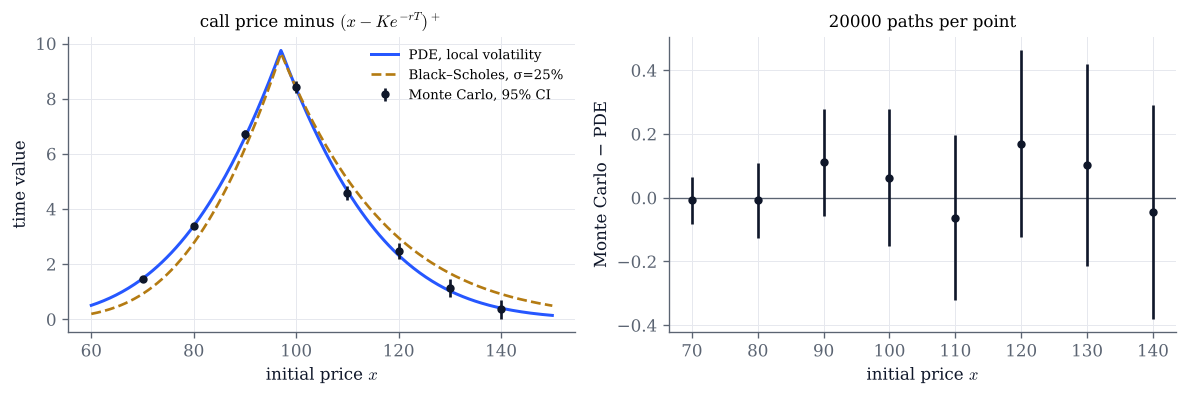

In [2]:
def mc_vs_pde(level=0.25, skew=0.12, K=100.0, T=1.0, r=0.03, n_paths=20_000, seed=0):
    vol = lambda t, x: skew_vol(t, x, level=level, skew=skew)
    g = lambda x: np.maximum(x - K, 0.0)
    res = solve_pricing_pde(g, T, r, vol, 5.0, 2000.0, n_x=800, n_t=200)
    spots = np.arange(70.0, 141.0, 10.0)
    mc = [local_vol_mc(g, s, T, r, vol, 50, n_paths, seed=seed + i) for i, s in enumerate(spots)]
    est = np.array([m["mean"] for m in mc]); se = np.array([m["se"] for m in mc])
    xs = np.linspace(60, 150, 300)
    intrinsic = lambda x: np.maximum(x - K * np.exp(-r * T), 0.0)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(xs, price_at(res, xs) - intrinsic(xs), color=COBALT, lw=1.8, label="PDE, local volatility")
    ax.plot(xs, call(xs, K, T, r, level) - intrinsic(xs), color=GOLD, ls="--", label=f"Black–Scholes, σ={level:.0%}")
    ax.errorbar(spots, est - intrinsic(spots), yerr=1.96 * se, fmt="o", ms=4, color=INK, label="Monte Carlo, 95% CI")
    ax.set(xlabel="initial price $x$", ylabel="time value", title="call price minus $(x-Ke^{-rT})^+$")
    ax.legend(fontsize=8)
    ax2.axhline(0, color=GREY, lw=0.8)
    ax2.errorbar(spots, est - price_at(res, spots), yerr=1.96 * se, fmt="o", ms=4, color=INK)
    ax2.set(xlabel="initial price $x$", ylabel="Monte Carlo − PDE", title=f"{n_paths} paths per point")
    fig.tight_layout()
    plt.show()

mc_vs_pde()

In [3]:
# Explore: with skew = 0 the model is Black–Scholes and the two curves on the left coincide.
# How do the confidence intervals shrink when you multiply the number of paths by 4?
interact(mc_vs_pde,
         level=FloatSlider(value=0.25, min=0.15, max=0.40, step=0.01, continuous_update=False, description="level"),
         skew=FloatSlider(value=0.12, min=0.0, max=0.14, step=0.01, continuous_update=False, description="skew"),
         K=FloatSlider(value=100.0, min=80.0, max=120.0, step=5.0, continuous_update=False, description="K"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         r=FloatSlider(value=0.03, min=-0.02, max=0.08, step=0.01, continuous_update=False, description="r"),
         n_paths=IntSlider(value=20_000, min=5_000, max=80_000, step=5_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

## 2. A local volatility price surface

One solution of the pricing equation gives the whole function $(t,x)\mapsto v(t,x)$. On the left, the call price
as a function of time and stock price; on the right, its difference from Black–Scholes at the volatility
$\sigma(100)$, at three times to maturity. With a downward skew the volatility is higher below $100$ and lower above,
and the call is worth more than in Black–Scholes when the stock is below the strike and less when it is above.

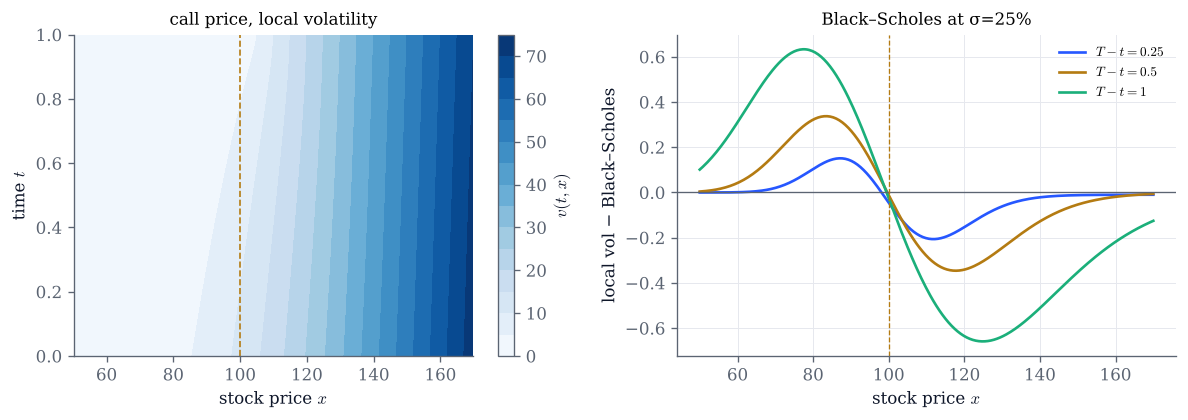

In [4]:
def surface(level=0.25, skew=0.12, slope=2.0, K=100.0, T=1.0, r=0.03):
    vol = lambda t, x: skew_vol(t, x, level=level, skew=skew, slope=slope)
    res = solve_pricing_pde(lambda x: np.maximum(x - K, 0.0), T, r, vol, 5.0, 2000.0, n_x=600, n_t=150, keep=True)
    keep = (res["x"] > 50) & (res["x"] < 170)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
    cs = ax.contourf(res["x"][keep], res["t"], res["surface"][:, keep], levels=16, cmap="Blues")
    fig.colorbar(cs, ax=ax, label="$v(t,x)$")
    ax.axvline(K, color=GOLD, ls="--", lw=1)
    ax.set(xlabel="stock price $x$", ylabel="time $t$", title="call price, local volatility")
    ax.grid(False)
    xs = np.linspace(50, 170, 300)
    for frac, c in ((0.25, COBALT), (0.5, GOLD), (1.0, GREEN)):
        tau = frac * T
        row = np.argmin(np.abs(res["t"] - (T - tau)))
        v = price_at(dict(x=res["x"], v=res["surface"][row]), xs)
        ax2.plot(xs, v - call(xs, K, tau, r, level), color=c, label=f"$T-t={tau:.2g}$")
    ax2.axhline(0, color=GREY, lw=0.8); ax2.axvline(K, color=GOLD, ls="--", lw=0.8)
    ax2.set(xlabel="stock price $x$", ylabel="local vol − Black–Scholes", title=f"Black–Scholes at σ={level:.0%}")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

surface()

In [5]:
# Explore: a negative skew gives an upward-sloping volatility; slope controls how fast it changes with the price.
interact(surface,
         level=FloatSlider(value=0.25, min=0.15, max=0.40, step=0.01, continuous_update=False, description="level"),
         skew=FloatSlider(value=0.12, min=-0.12, max=0.14, step=0.01, continuous_update=False, description="skew"),
         slope=FloatSlider(value=2.0, min=0.5, max=5.0, step=0.25, continuous_update=False, description="slope"),
         K=FloatSlider(value=100.0, min=80.0, max=120.0, step=5.0, continuous_update=False, description="K"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         r=FloatSlider(value=0.03, min=-0.02, max=0.08, step=0.01, continuous_update=False, description="r"));

## 3. Transition densities and Kolmogorov's equations

The transition density $p(t,x;s,y)$ of geometric Brownian motion $dS=\mu S\,dt+\sigma S\,dW$ is a function of the
starting point $(t,x)$ and of the arrival point $(s,y)$ (Theorem 12.8, Example 12.9):

* **forward:** $y\mapsto p(0,x_0;s,y)$ is a probability density, which solves
  $\partial_sp=\tfrac12\partial_{yy}(\sigma^2y^2p)-\partial_y(\mu yp)$; the histogram is of exact samples of $S_s$;
* **backward:** $x\mapsto p(t,x;T,y_0)$ is not a density in $x$, and solves
  $\partial_tp+\mu x\,\partial_xp+\tfrac12\sigma^2x^2\partial_{xx}p=0$.

The printed residuals are the two equations evaluated by finite differences: they vanish up to discretisation error,
compared with the size of the time derivative, also printed.

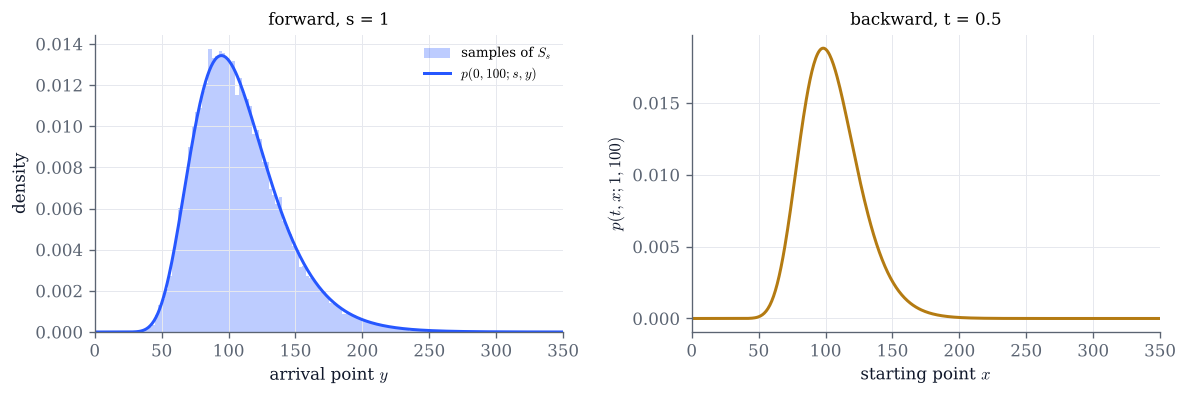

at (t,x;s,y) = (0,100;1,110):  backward residual +1.7e-08,  forward residual -5.3e-09,  |d_s p| = 5.4e-03
at (t,x;s,y) = (0.5,90;1,100):  backward residual +8.3e-08,  forward residual -9.1e-09,  |d_s p| = 1.3e-02


In [6]:
def kolmogorov(mu=0.08, sigma=0.3, s=1.0, t=0.5, seed=1):
    x0, y0, T = 100.0, 100.0, 1.0
    rng = np.random.default_rng(seed)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    S = x0 * np.exp((mu - 0.5 * sigma**2) * s + sigma * np.sqrt(s) * rng.normal(size=40_000))
    y = np.linspace(1, 350, 500)
    ax.hist(S, bins=np.linspace(0, 350, 141), density=True, color=COBALT, alpha=0.3, label="samples of $S_s$")
    ax.plot(y, gbm_density(0.0, x0, s, y, mu, sigma), color=COBALT, lw=1.8, label="$p(0,100;s,y)$")
    ax.set(xlabel="arrival point $y$", ylabel="density", title=f"forward, s = {s:g}", xlim=(0, 350))
    ax.legend(fontsize=8)
    x = np.linspace(1, 350, 500)
    ax2.plot(x, gbm_density(t, x, T, y0, mu, sigma), color=GOLD, lw=1.8)
    ax2.set(xlabel="starting point $x$", ylabel="$p(t,x;1,100)$", title=f"backward, t = {t:g}", xlim=(0, 350))
    fig.tight_layout()
    plt.show()
    dens = lambda a, b, c, d: gbm_density(a, b, c, d, mu, sigma)
    b, sg = (lambda tt, xx: mu * xx), (lambda tt, xx: sigma * xx)
    for (ta, xa, sa, ya) in ((0.0, x0, s, 110.0), (t, 90.0, T, y0)):
        back, fwd = kolmogorov_residuals(dens, b, sg, ta, xa, sa, ya)
        h = 1e-4
        size = abs(dens(ta, xa, sa + h, ya) - dens(ta, xa, sa - h, ya)) / (2 * h)
        print(f"at (t,x;s,y) = ({ta:g},{xa:g};{sa:g},{ya:g}):  backward residual {back:+.1e},  "
              f"forward residual {fwd:+.1e},  |d_s p| = {size:.1e}")

kolmogorov()

In [7]:
# Explore: as s grows the density in y spreads and drifts; as t decreases the function of x spreads.
interact(kolmogorov,
         mu=FloatSlider(value=0.08, min=-0.2, max=0.3, step=0.02, continuous_update=False, description="μ"),
         sigma=FloatSlider(value=0.3, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         s=FloatSlider(value=1.0, min=0.05, max=5.0, step=0.05, continuous_update=False, description="s"),
         t=FloatSlider(value=0.5, min=0.0, max=0.95, step=0.05, continuous_update=False, description="t"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 4. The heat kernel smooths, and the digital's delta is a density

By Proposition 12.7, Black–Scholes prices are heat-kernel averages of the payoff: even the digital call, whose payoff
jumps at $K$, has a smooth price before maturity. The price of this irregularity is paid near maturity: the delta of the
digital equals $e^{-r\tau}\frac Kx\,p(t,x;T,K)$, the discounted transition density of the stock at the strike
(Proposition 12.11), and it concentrates and grows like $1/(K\sigma\sqrt{2\pi\tau})$ as $\tau=T-t\to0$.
The dots on the right are finite-difference derivatives of the price; the line is the density formula.

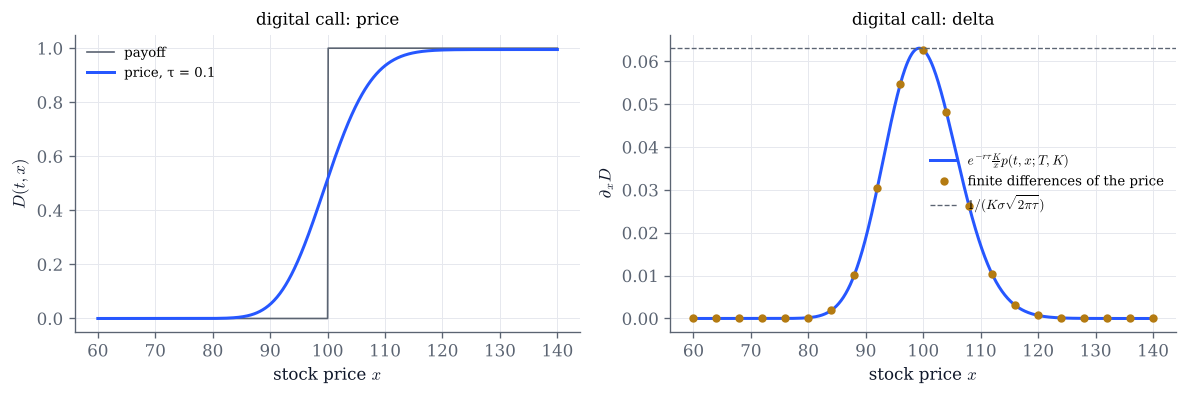

In [8]:
def digital(tau=0.1, sigma=0.2, r=0.05, K=100.0):
    x = np.linspace(0.6 * K, 1.4 * K, 801)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(x, (x > K).astype(float), color=GREY, lw=1, label="payoff")
    ax.plot(x, digital_call(x, K, tau, r, sigma), color=COBALT, lw=1.8, label=f"price, τ = {tau:g}")
    ax.set(xlabel="stock price $x$", ylabel="$D(t,x)$", title="digital call: price")
    ax.legend(fontsize=8)
    ax2.plot(x, digital_delta(x, K, tau, r, sigma), color=COBALT, lw=1.8, label=r"$e^{-r\tau}\frac{K}{x}p(t,x;T,K)$")
    xd = x[::40]; h = 1e-3 * K
    fd = (digital_call(xd + h, K, tau, r, sigma) - digital_call(xd - h, K, tau, r, sigma)) / (2 * h)
    ax2.plot(xd, fd, "o", ms=4, color=GOLD, label="finite differences of the price")
    ax2.axhline(1 / (K * sigma * np.sqrt(2 * np.pi * tau)), color=GREY, ls="--", lw=0.8, label=r"$1/(K\sigma\sqrt{2\pi\tau})$")
    ax2.set(xlabel="stock price $x$", ylabel=r"$\partial_x D$", title="digital call: delta")
    ax2.legend(fontsize=8, loc="center right")
    fig.tight_layout()
    plt.show()

digital()

In [9]:
# Explore: move tau towards 0 and watch the peak of the delta grow like 1/sqrt(tau).
interact(digital,
         tau=FloatSlider(value=0.1, min=0.001, max=2.0, step=0.001, readout_format=".3f", continuous_update=False, description="τ"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=-0.02, max=0.1, step=0.01, continuous_update=False, description="r"),
         K=FloatSlider(value=100.0, min=80.0, max=120.0, step=5.0, continuous_update=False, description="K"));

## Things to try

- In section 1, set the skew to $0$. Which theorem says that the PDE solution is then the Black–Scholes formula?
  Then set the skew back and increase $T$: why does the difference between the two models grow with maturity?
- In section 1, the Monte Carlo estimates use an Euler scheme with $50$ steps. Their bias is invisible here. Why is it
  much smaller than the statistical error, and how could you make it visible?
- In section 2, choose a negative skew (volatility rising with the price). On which side of the strike is the call now
  worth more than in Black–Scholes?
- In section 3, set $\mu=\sigma^2/2$. What is the median of $S_s$, and where does the forward density peak?
- In section 4, compare the delta of the digital with the gamma of a call with the same strike (`greeks` in
  `ieor222.blackscholes`). Why do they look alike near maturity?